# APD peaks → Phantom TMX event clips

This notebook reads a Vision Research Phantom `.cine` recording, detects peaks in the simultaneously recorded APD signal, assigns every APD peak to the corresponding Phantom frame, and extracts a short video clip around each event.

Synchronization uses two independent pieces of information:

1. The APD `.npz` contains the NI trigger time relative to the start of the NI acquisition.
2. The CINE header contains each frame timestamp relative to the Phantom trigger.

A shared trigger therefore maps the Phantom frame clock onto the APD time axis. The recorded `camera_frame_signal`, when present, is shown as a validation signal. `SYNC_OFFSET_MS` allows a measured fixed correction.

Event clips can be cropped spatially and temporally. Multi-page TIFF is the recommended scientific output because it preserves the original bit depth. Optional MP4 files are contrast-scaled 8-bit previews only.


Set `ROOT` to the recording folder and run all cells to process every unambiguous APD/CINE match, including subfolders. Each pair gets its own output folder and a row in the batch summary.


## Environment
Select **Python (APD Phantom CINE)** as the notebook kernel. The local environment is installed at `C:\Users\labfischer\.venvs\apd-phantom-cine`.

In [66]:
from pathlib import Path
import json
import math
import re
import warnings

import imageio.v2 as imageio
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
import pandas as pd
from pims import Cine
from IPython.display import HTML, display
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import linear_sum_assignment
from scipy.signal import find_peaks, peak_widths
import tifffile

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

## Discover and pair recordings

Automatic pairing uses filenames. It first looks for an identical filename stem and otherwise compares the last number contained in each name. For example, `sample_012.npz` matches `sample_012.cine`, and `APD_012.npz` can match `Phantom_012.cine`. Ambiguous names are never accepted automatically. Inspect the table before continuing.

In [103]:
ROOT = Path(r'd:\Luise\APD\170926\NIH3T3')  # Change this if the data are stored elsewhere.
NAME_MATCH_MODE = "last_number"  # "last_number" or "exact_stem"

def filename_key(path: Path, mode="last_number"):
    stem = path.stem.casefold()
    if mode == "exact_stem":
        return stem
    if mode == "last_number":
        numbers = re.findall(r"\d+", stem)
        return str(int(numbers[-1])) if numbers else None
    raise ValueError(f"Unknown NAME_MATCH_MODE: {mode}")

def discover_and_pair(root: Path, mode="last_number"):
    root = Path(root).expanduser().resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"Recording folder not found: {root}. Set ROOT to your data folder.")
    npz_paths = sorted(p for p in root.rglob("*.npz") if not p.name.startswith("._"))
    cine_paths = sorted(p for p in root.rglob("*.cine") if not p.name.startswith("._"))
    cine_paths += sorted(p for p in root.rglob("*.CINE") if not p.name.startswith("._"))
    cine_paths = list(dict.fromkeys(cine_paths))

    columns = ["apd_file", "matching_key", "cine_file", "match_method",
               "status", "apd_path", "cine_path"]
    cine_by_key = {}
    for path in cine_paths:
        cine_by_key.setdefault(filename_key(path, mode), []).append(path)
    used_cine, rows = set(), []
    for apd_path in npz_paths:
        key = filename_key(apd_path, mode)
        exact = [p for p in cine_paths if p.stem.casefold() == apd_path.stem.casefold() and p not in used_cine]
        candidates = exact if exact else [p for p in (cine_by_key.get(key, []) if key is not None else []) if p not in used_cine]
        if len(candidates) == 1:
            cine_path = candidates[0]; used_cine.add(cine_path)
            status = "matched"; method = "exact stem" if exact else mode
        elif len(candidates) > 1:
            cine_path = None; status = f"AMBIGUOUS ({len(candidates)} CINE files)"; method = mode
        else:
            cine_path = None; status = "UNMATCHED"; method = mode
        rows.append({"apd_file": apd_path.name, "matching_key": key,
                     "cine_file": cine_path.name if cine_path else None, "match_method": method,
                     "status": status, "apd_path": str(apd_path.resolve()),
                     "cine_path": str(cine_path.resolve()) if cine_path else None})
    unused = [str(p.resolve()) for p in cine_paths if p not in used_cine]
    return pd.DataFrame(rows, columns=columns), unused, []

pair_table, unused_cine_files, discovery_errors = discover_and_pair(ROOT, NAME_MATCH_MODE)
display(pair_table.drop(columns=["apd_path", "cine_path"], errors="ignore"))
print(f"Unused CINE files: {len(unused_cine_files)}")
if discovery_errors:
    print("Files skipped during discovery:")
    print("\n".join(discovery_errors))

,apd_file,matching_key,cine_file,match_method,status
0,100_50.npz,50,100_50.cine,exact stem,matched
1,200_100.npz,100,200_100.cine,exact stem,matched
2,400_200.npz,200,400_200.cine,exact stem,matched
3,600_400.npz,400,600_400.cine,exact stem,matched


Unused CINE files: 0


## Configuration
These settings apply to **every matched pair** found under `ROOT`. Unmatched or ambiguous rows are skipped. Positive `SYNC_OFFSET_MS` moves Phantom frames later on the APD clock.

`CROP_YX` uses `(y_start, y_stop, x_start, x_stop)` in NumPy pixel coordinates. Set `SHOW_PREVIEWS = True` to inspect plots and example clips for each pair; leave it `False` for a quieter batch run.

Outputs are saved under `OUTPUT_ROOT / <relative APD subfolder> / <APD stem>`. This keeps recordings with the same filename in different subfolders separate. `batch_summary.csv` records successes and failures. A failed pair may leave partial outputs in its folder. Rerunning uses the same output folders; choose a new `OUTPUT_ROOT` when retaining an earlier run.

In [104]:
# Synchronization
SYNC_OFFSET_MS = 0.0
CAMERA_ACTIVE_LOW = True
SYNC_PLOT_WINDOW_MS = 10.0

# APD peak detection
SMOOTH_MS = 0.05
HEIGHT_SIGMA = 6.0
PROMINENCE_SIGMA = 4.0
ABSOLUTE_HEIGHT_V = 0.15  # Fixed APD peak threshold in volts; set None for HEIGHT_SIGMA mode.
MIN_PEAK_DISTANCE_MS = 0.25

# Event clip: time before the APD peak, then additional frames after the detected peak end
PRE_PEAK_MS = 1.0
POST_PEAK_MS = 1.0  # Optional minimum time after the peak centre.
EXTRA_FRAMES_AFTER_PEAK_END = 50
PEAK_END_RELATIVE_HEIGHT = 0.95  # Peak end near the baseline (0=top, 1=prominence base).
CROP_YX = None  # Example: (100, 350, 50, 600)
MAX_FRAMES_PER_CLIP = 2000

# Notebook previews
SHOW_PREVIEWS = False
NUMBER_OF_EXAMPLES = 3
STILLS_PER_EXAMPLE = 5
ANIMATE_FIRST_EXAMPLE = True
MAX_ANIMATION_FRAMES = 100
PREVIEW_FPS = 20
DISPLAY_PERCENTILES = (1.0, 99.8)  # Display only; never changes raw data.

# Export
SAVE_EVENT_CLIPS = True
SAVE_TIFF = True          # Lossless, original bit depth; recommended.
SAVE_MP4_PREVIEW = False # 8-bit contrast-scaled preview.
MP4_PLAYBACK_FPS = 30
OUTPUT_ROOT = ROOT / "phantom_event_clips_single"

## Process one pair
Run this cell once to define the processing function used by both the threshold preview and the batch.

In [105]:
def process_pair(apd_path, cine_path, output_dir, match_method, show_previews=False, threshold_preview=False,
                 preview_center_s=None, preview_window_ms=20.0):
    """Process one recording pair and always release its CINE handle."""
    apd_path, cine_path = Path(apd_path), Path(cine_path)
    OUTPUT_DIR = Path(output_dir)
    cine = None
    previous_figures = set(plt.get_fignums())
    try:
        with np.load(apd_path, allow_pickle=False) as data:
            required = {"time_s", "photodiode_signal"}
            missing = required.difference(data.files)
            if missing:
                raise KeyError(f"Missing APD arrays: {sorted(missing)}")
            time_s = np.asarray(data["time_s"], dtype=float)
            apd_signal = np.asarray(data["photodiode_signal"], dtype=float)
            camera_signal = np.asarray(data["camera_frame_signal"], dtype=float) if "camera_frame_signal" in data.files else None
            apd_metadata = json.loads(str(data["metadata_json"].item())) if "metadata_json" in data.files else {}
        if len(time_s) != len(apd_signal) or (camera_signal is not None and len(camera_signal) != len(time_s)):
            raise ValueError("APD, time, and optional camera signal arrays must have equal lengths.")
        sample_interval_s = float(np.median(np.diff(time_s)))
        sample_rate_hz = 1.0 / sample_interval_s
        trigger_time_apd_s = apd_metadata.get("trigger_time_from_acquisition_start_s")
        if trigger_time_apd_s is None:
            raise KeyError("metadata_json has no trigger_time_from_acquisition_start_s; a shared-trigger mapping cannot be made safely.")
        trigger_time_apd_s = float(trigger_time_apd_s)
        print(f"APD samples: {len(time_s):,}; rate: {sample_rate_hz:,.1f} Hz; trigger: {trigger_time_apd_s:.6f} s")

        cine = Cine(str(cine_path))
        try:
            cine_trigger = cine.trigger_time
            trigger_datetime = cine_trigger["datetime"]
            trigger_fraction = float(cine_trigger["second_fraction"])
            # Work relative to the trigger. Calling datetime.timestamp() for millions of frames is very slow.
            cine_time_to_trigger_s = np.fromiter(
                ((dt-trigger_datetime).total_seconds() + float(frac)-trigger_fraction
                 for dt, frac in cine.frame_time_stamps),
                dtype=np.float64, count=len(cine.frame_time_stamps),
            )
        except Exception:
            raise
        if len(cine_time_to_trigger_s) != len(cine):
            raise RuntimeError("CINE timestamp count does not equal its frame count.")
        if np.any(np.diff(cine_time_to_trigger_s) <= 0):
            raise RuntimeError("CINE frame timestamps are not strictly increasing.")
        frame_times_apd_s = trigger_time_apd_s + cine_time_to_trigger_s + SYNC_OFFSET_MS / 1000.0
        cine_frame_period_s = float(np.median(np.diff(cine_time_to_trigger_s)))
        actual_fps = 1.0 / cine_frame_period_s
        first_frame = np.asarray(cine[0])
        overlap_start_s = max(time_s[0], frame_times_apd_s[0])
        overlap_end_s = min(time_s[-1], frame_times_apd_s[-1] + cine_frame_period_s)
        if overlap_end_s <= overlap_start_s:
            raise RuntimeError("APD and CINE time ranges do not overlap. Check the pair and SYNC_OFFSET_MS.")
        print(f"CINE frames: {len(cine):,}; frame shape/dtype: {first_frame.shape}, {first_frame.dtype}")
        print(f"Header FPS: {cine.frame_rate:,.3f}; timestamp FPS: {actual_fps:,.3f}")
        print(f"Frames relative to trigger: {cine_time_to_trigger_s[0]:.6f} to {cine_time_to_trigger_s[-1]:.6f} s")
        print(f"Overlap on APD clock: {overlap_start_s:.6f} to {overlap_end_s:.6f} s")

        def apply_crop(frame, crop_yx):
            if crop_yx is None:
                return np.asarray(frame)
            y0, y1, x0, x1 = map(int, crop_yx)
            if not (0 <= y0 < y1 <= frame.shape[0] and 0 <= x0 < x1 <= frame.shape[1]):
                raise ValueError(f"CROP_YX {crop_yx} is outside frame shape {frame.shape}.")
            return np.asarray(frame)[y0:y1, x0:x1, ...]

        if show_previews:
            fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
            display_frame = apply_crop(first_frame, None)
            lo, hi = np.percentile(display_frame, DISPLAY_PERCENTILES)
            ax.imshow(display_frame, cmap="gray", vmin=lo, vmax=hi, origin="upper")
            ax.set(title="First Phantom frame — use axes to choose CROP_YX", xlabel="x (pixel)", ylabel="y (pixel)")
            if CROP_YX is not None:
                y0, y1, x0, x1 = CROP_YX
                ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, color="red", lw=2))
            plt.show()

        if show_previews:
            def two_level_threshold(signal, iterations=30):
                finite = np.asarray(signal[np.isfinite(signal)], dtype=float)
                centers = np.array([np.percentile(finite, 0.1), np.percentile(finite, 99.9)])
                for _ in range(iterations):
                    low = np.abs(finite - centers[0]) <= np.abs(finite - centers[1])
                    if low.all() or (~low).all(): break
                    updated = np.array([finite[low].mean(), finite[~low].mean()])
                    if np.allclose(updated, centers, rtol=1e-8, atol=1e-10): centers = updated; break
                    centers = updated
                centers.sort(); return float(centers.mean()), centers

            if camera_signal is None:
                print("No camera_frame_signal exists in the NPZ; synchronization relies on the common trigger only.")
            else:
                camera_threshold, camera_levels = two_level_threshold(camera_signal)
                active = camera_signal < camera_threshold if CAMERA_ACTIVE_LOW else camera_signal > camera_threshold
                edge_samples = np.flatnonzero(np.diff(active.astype(np.int8)) == 1) + 1
                edge_times = time_s[edge_samples]
                center = trigger_time_apd_s
                half_window = SYNC_PLOT_WINDOW_MS / 2000.0
                mask = (time_s >= center-half_window) & (time_s <= center+half_window)
                frame_mask = (frame_times_apd_s >= center-half_window) & (frame_times_apd_s <= center+half_window)
                fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
                ax.plot(time_s[mask], camera_signal[mask], color="black", lw=0.8, label="NI camera signal")
                for k, ft in enumerate(frame_times_apd_s[frame_mask]):
                    ax.axvline(ft, color="tab:red", alpha=0.35, lw=0.7, label="CINE frame time" if k == 0 else None)
                ax.axvline(trigger_time_apd_s, color="tab:blue", ls="--", label="shared trigger")
                ax.set(xlabel="APD/NI time (s)", ylabel="camera signal (V)", title="Synchronization around trigger")
                ax.legend(); plt.show()
                print(f"Camera levels: {camera_levels[0]:.3f}, {camera_levels[1]:.3f} V; detected edges: {len(edge_times):,}")

        def nearest_sorted_indices(sorted_values, query_values):
            right = np.searchsorted(sorted_values, query_values, side="left")
            right = np.clip(right, 0, len(sorted_values)-1)
            left = np.clip(right-1, 0, len(sorted_values)-1)
            choose_left = np.abs(query_values-sorted_values[left]) <= np.abs(sorted_values[right]-query_values)
            return np.where(choose_left, left, right)

        sigma_samples = max(0.5, (SMOOTH_MS/1000.0)/sample_interval_s)
        apd_filtered = gaussian_filter1d(apd_signal, sigma_samples)
        in_overlap = (time_s >= overlap_start_s) & (time_s < overlap_end_s)
        baseline = float(np.median(apd_filtered[in_overlap]))
        noise_sigma = float(1.4826*np.median(np.abs(apd_filtered[in_overlap]-baseline)))
        height_threshold_v = float(ABSOLUTE_HEIGHT_V) if ABSOLUTE_HEIGHT_V is not None else baseline + HEIGHT_SIGMA*noise_sigma
        distance_samples = max(1, round((MIN_PEAK_DISTANCE_MS/1000.0)/sample_interval_s))
        all_peaks, props = find_peaks(apd_filtered, height=height_threshold_v,
                                      prominence=PROMINENCE_SIGMA*noise_sigma, distance=distance_samples)
        # right_ips estimates where each peak has returned close to its local baseline.
        _, _, _, all_right_ips = peak_widths(apd_filtered, all_peaks, rel_height=PEAK_END_RELATIVE_HEIGHT,
                                              prominence_data=(props["prominences"],
                                                               props["left_bases"], props["right_bases"]))
        keep = in_overlap[all_peaks]
        peaks = all_peaks[keep]; prominences = props["prominences"][keep]; right_ips = all_right_ips[keep]
        peak_times_s = time_s[peaks]
        peak_end_times_s = np.interp(right_ips, np.arange(len(time_s)), time_s)
        center_frames = nearest_sorted_indices(frame_times_apd_s, peak_times_s)
        peak_end_frames = nearest_sorted_indices(frame_times_apd_s, peak_end_times_s)
        clip_start_frames = np.searchsorted(frame_times_apd_s, peak_times_s-PRE_PEAK_MS/1000.0, side="left")
        clip_stop_from_time = np.searchsorted(frame_times_apd_s, peak_times_s+POST_PEAK_MS/1000.0, side="right")
        # stop is exclusive: include the peak-end frame plus exactly the requested number of later frames.
        clip_stop_from_peak_end = peak_end_frames + 1 + int(EXTRA_FRAMES_AFTER_PEAK_END)
        clip_stop_frames = np.maximum(clip_stop_from_time, clip_stop_from_peak_end)
        clip_start_frames = np.clip(clip_start_frames, 0, len(cine))
        clip_stop_frames = np.clip(clip_stop_frames, 0, len(cine))
        # Even if the requested window is shorter than one frame period, always include the nearest frame.
        clip_start_frames = np.minimum(clip_start_frames, center_frames)
        clip_stop_frames = np.maximum(clip_stop_frames, center_frames + 1)
        event_table = pd.DataFrame({
            "event_id": np.arange(1, len(peaks)+1), "peak_sample": peaks, "peak_time_s": peak_times_s,
            "peak_end_time_s": peak_end_times_s, "apd_raw_v": apd_signal[peaks], "apd_filtered_v": apd_filtered[peaks],
            "prominence_v": prominences, "center_cine_frame": center_frames,
            "peak_end_cine_frame": peak_end_frames,
            "center_frame_time_s": frame_times_apd_s[center_frames] if len(center_frames) else np.array([]),
            "peak_minus_frame_ms": 1000*(peak_times_s-frame_times_apd_s[center_frames]) if len(center_frames) else np.array([]),
            "clip_start_frame": clip_start_frames, "clip_stop_frame_exclusive": clip_stop_frames,
            "clip_frame_count": clip_stop_frames-clip_start_frames,
            "frames_after_peak_end": np.maximum(0, clip_stop_frames-peak_end_frames-1),
        })
        print(f"APD baseline: {baseline:.6g} V; noise σ: {noise_sigma:.6g} V; height threshold: {height_threshold_v:.6g} V")
        print(f"Detected {len(event_table)} event(s) in the APD/CINE overlap.")
        if show_previews:
            display(event_table)
        if len(event_table) and event_table["clip_frame_count"].max() > MAX_FRAMES_PER_CLIP:
            warnings.warn("At least one clip exceeds MAX_FRAMES_PER_CLIP. Shorten PRE/POST_PEAK_MS or raise the limit deliberately.")

        if threshold_preview:
            if not np.isfinite(preview_window_ms) or preview_window_ms <= 0:
                raise ValueError("PREVIEW_WINDOW_MS must be positive and finite.")
            if preview_center_s is None:
                center_index = int(peaks[np.argmax(apd_filtered[peaks])]) if len(peaks) else int(np.flatnonzero(in_overlap)[np.argmax(apd_filtered[in_overlap])])
                preview_center_s = float(time_s[center_index])
            if not overlap_start_s <= preview_center_s <= overlap_end_s:
                raise ValueError("PREVIEW_CENTER_S must lie within the APD/CINE overlap.")
            half_window = preview_window_ms / 2000.0
            fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
            for ax in axes:
                ax.plot(time_s, apd_signal, color="0.7", lw=0.7, label="raw APD")
                ax.plot(time_s, apd_filtered, color="black", lw=0.9, label="smoothed APD")
                ax.axhline(height_threshold_v, color="tab:orange", ls="--",
                           label=f"height threshold: {height_threshold_v:.4g} V")
                ax.scatter(peak_times_s, apd_filtered[peaks], color="tab:red", s=30,
                           zorder=3, label=f"accepted peaks: {len(peaks)}")
                ax.set(xlabel="APD/NI time (s)", ylabel="APD signal (V)")
                ax.legend(loc="upper right")
            axes[0].set(xlim=(overlap_start_s, overlap_end_s), title=f"{apd_path.name}: full overlap")
            zoom_start = max(overlap_start_s, preview_center_s-half_window)
            zoom_end = min(overlap_end_s, preview_center_s+half_window)
            axes[0].axvspan(zoom_start, zoom_end, color="tab:blue", alpha=0.12)
            axes[1].set(xlim=(zoom_start, zoom_end), title="Example event / threshold detail")
            zoom_mask = (time_s >= zoom_start) & (time_s <= zoom_end)
            if np.any(zoom_mask):
                low = min(float(apd_signal[zoom_mask].min()), float(apd_filtered[zoom_mask].min()), height_threshold_v)
                high = max(float(apd_signal[zoom_mask].max()), float(apd_filtered[zoom_mask].max()), height_threshold_v)
                margin = max((high-low)*0.1, 0.001)
                axes[1].set_ylim(low-margin, high+margin)
            plt.show()
            print(f"Height threshold: {height_threshold_v:.6g} V; prominence threshold: {PROMINENCE_SIGMA*noise_sigma:.6g} V; minimum spacing: {MIN_PEAK_DISTANCE_MS:g} ms")
            print("Preview only: no clips or output files were written. Adjust ABSOLUTE_HEIGHT_V below and rerun this preview cell.")
            if not len(peaks):
                print("No accepted peaks. The zoom shows the strongest signal in the overlap; try lowering the height or prominence threshold.")
            return {"event_count": len(event_table), "height_threshold_v": height_threshold_v,
                    "event_table": event_table, "exported": False}

        if show_previews:
            fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
            ax.plot(time_s, apd_filtered, color="black", lw=0.7, label="filtered APD")
            ax.axhline(height_threshold_v, color="tab:orange", ls="--", label="height threshold")
            if len(peaks):
                ax.scatter(peak_times_s, apd_filtered[peaks], color="tab:red", s=24, zorder=3, label="accepted peaks")
                for _, row in event_table.iterrows():
                    start_t = frame_times_apd_s[int(row.clip_start_frame)]
                    stop_i = min(int(row.clip_stop_frame_exclusive), len(frame_times_apd_s)-1)
                    stop_t = frame_times_apd_s[stop_i] if stop_i < len(frame_times_apd_s) else frame_times_apd_s[-1]+cine_frame_period_s
                    ax.axvspan(start_t, stop_t, color="tab:green", alpha=0.08)
            ax.set(xlim=(overlap_start_s, overlap_end_s), xlabel="APD/NI time (s)", ylabel="APD signal (V)",
                   title="APD peaks and extracted Phantom clip windows")
            ax.legend(); plt.show()

        def load_cine_clip(reader, start, stop, crop_yx=None):
            start, stop = int(start), int(stop)
            if stop <= start:
                raise ValueError("Empty event clip. Increase PRE_PEAK_MS or POST_PEAK_MS.")
            if stop-start > MAX_FRAMES_PER_CLIP:
                raise ValueError(f"Clip has {stop-start} frames, exceeding MAX_FRAMES_PER_CLIP={MAX_FRAMES_PER_CLIP}.")
            return np.stack([apply_crop(np.asarray(reader[i]), crop_yx) for i in range(start, stop)])

        if show_previews:
            example_rows = event_table.nlargest(min(NUMBER_OF_EXAMPLES, len(event_table)), "apd_filtered_v")
            example_clips = {}
            for _, row in example_rows.iterrows():
                clip = load_cine_clip(cine, row.clip_start_frame, row.clip_stop_frame_exclusive, CROP_YX)
                example_clips[int(row.event_id)] = clip
                count = min(STILLS_PER_EXAMPLE, len(clip))
                indices = np.unique(np.linspace(0, len(clip)-1, count).round().astype(int))
                lo, hi = np.percentile(clip[indices], DISPLAY_PERCENTILES)
                fig, axes = plt.subplots(1, len(indices), figsize=(3.2*len(indices), 3.2), squeeze=False, constrained_layout=True)
                for ax, local_i in zip(axes.flat, indices):
                    absolute_i = int(row.clip_start_frame) + int(local_i)
                    ax.imshow(clip[local_i], cmap="gray", vmin=lo, vmax=hi)
                    relative_ms = 1000*(frame_times_apd_s[absolute_i]-row.peak_time_s)
                    ax.set_title(f"frame {absolute_i}\n{relative_ms:+.3f} ms")
                    ax.axis("off")
                fig.suptitle(f"Event {int(row.event_id)} — APD peak {row.apd_filtered_v:.4g} V")
                plt.show()
            if example_rows.empty:
                print("No events to preview. Check the APD threshold and synchronization.")

        if show_previews:
            if ANIMATE_FIRST_EXAMPLE and example_clips:
                event_id = next(iter(example_clips))
                clip = example_clips[event_id]
                step = max(1, math.ceil(len(clip)/MAX_ANIMATION_FRAMES))
                preview = clip[::step]
                lo, hi = np.percentile(preview, DISPLAY_PERCENTILES)
                fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
                artist = ax.imshow(preview[0], cmap="gray", vmin=lo, vmax=hi, animated=True)
                title = ax.set_title(f"Event {event_id}")
                ax.axis("off")
                def update_preview(i):
                    artist.set_data(preview[i]); title.set_text(f"Event {event_id} — preview frame {i+1}/{len(preview)}")
                    return artist, title
                animation = FuncAnimation(fig, update_preview, frames=len(preview), interval=1000/PREVIEW_FPS, blit=False)
                display(HTML(animation.to_jshtml(fps=PREVIEW_FPS)))
                plt.close(fig)

        def clip_to_uint8(clip, percentiles=DISPLAY_PERCENTILES):
            lo, hi = np.percentile(clip, percentiles)
            if hi <= lo: hi = lo + 1
            return np.clip((clip.astype(np.float32)-lo)*255.0/(hi-lo), 0, 255).astype(np.uint8), float(lo), float(hi)

        def write_mp4(path, clip, fps):
            clip8, lo, hi = clip_to_uint8(clip)
            # H.264 commonly requires even image dimensions. Padding affects the preview only.
            pad_y = clip8.shape[1] % 2; pad_x = clip8.shape[2] % 2
            if pad_y or pad_x:
                pad = ((0, 0), (0, pad_y), (0, pad_x)) + (((0, 0),) if clip8.ndim == 4 else ())
                clip8 = np.pad(clip8, pad, mode="edge")
            # MPEG-4 Part 2 is broadly available in Conda's FFmpeg builds.
            with imageio.get_writer(path, fps=fps, codec="mpeg4", quality=8, macro_block_size=None) as writer:
                for frame in clip8: writer.append_data(frame)
            return lo, hi

        if SAVE_EVENT_CLIPS:
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            event_table.to_csv(OUTPUT_DIR/"events.csv", index=False)
            for _, row in event_table.iterrows():
                clip = load_cine_clip(cine, row.clip_start_frame, row.clip_stop_frame_exclusive, CROP_YX)
                stem = f"event_{int(row.event_id):04d}_peak_{row.peak_time_s:.6f}s_frame_{int(row.center_cine_frame):07d}"
                if SAVE_TIFF:
                    axes = "TYX" if clip.ndim == 3 else "TYXS"
                    photometric = "minisblack" if clip.ndim == 3 else "rgb"
                    tifffile.imwrite(OUTPUT_DIR/f"{stem}.tif", clip, photometric=photometric, compression="zlib",
                                       bigtiff=clip.nbytes > 3_500_000_000, metadata={"axes": axes, "fps": actual_fps})
                if SAVE_MP4_PREVIEW:
                    write_mp4(OUTPUT_DIR/f"{stem}.mp4", clip, MP4_PLAYBACK_FPS)
                print(f"Saved event {int(row.event_id)} ({len(clip)} frames)")
            settings = {"apd_path": str(apd_path), "cine_path": str(cine_path), "match_method": match_method, "sync_offset_ms": SYNC_OFFSET_MS,
                        "height_threshold_v": height_threshold_v, "pre_peak_ms": PRE_PEAK_MS,
                        "post_peak_ms": POST_PEAK_MS, "extra_frames_after_peak_end": EXTRA_FRAMES_AFTER_PEAK_END,
                        "peak_end_relative_height": PEAK_END_RELATIVE_HEIGHT,
                        "crop_yx": CROP_YX, "actual_fps": actual_fps,
                        "event_count": len(event_table), "tiff_is_raw": True, "mp4_is_contrast_scaled_8bit": True}
            (OUTPUT_DIR/"settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
            print(f"Finished: {OUTPUT_DIR.resolve()}")
        else:
            print("Export disabled. Set SAVE_EVENT_CLIPS = True to save the event clips.")
        return {"event_count": len(event_table), "actual_fps": actual_fps,
                "exported": bool(SAVE_EVENT_CLIPS)}
    finally:
        if cine is not None:
            cine.close()
        for figure_number in set(plt.get_fignums()) - previous_figures:
            plt.close(figure_number)

## Preview an example and adjust the threshold
Run this cell before starting the batch. It uses the same smoothing, height, prominence, spacing and APD/CINE overlap checks as batch processing, but **does not export files**.

The first plot shows the full overlap; the second zooms in on the strongest accepted event (or strongest signal if no peaks qualify). Orange is the height threshold; red dots are accepted peaks.

Edit `ABSOLUTE_HEIGHT_V` and rerun this cell until the red markers select the events you want. This value also applies to the subsequent batch. Set it to `None` to use `HEIGHT_SIGMA` instead. Peaks must also pass `PROMINENCE_SIGMA` and `MIN_PEAK_DISTANCE_MS` from Configuration.

Use `PREVIEW_PAIR_INDEX` to choose another pair from the displayed zero-based list. Set `PREVIEW_CENTER_S` to inspect a particular time and `PREVIEW_WINDOW_MS` to change the zoom width. Rerunning Configuration resets the threshold to its configured value.

,apd_file,cine_file,apd_path
PREVIEW_PAIR_INDEX,,,
0,100_50.npz,100_50.cine,D:\Luise\APD\170926\NIH3T3\100_50.npz
1,200_100.npz,200_100.cine,D:\Luise\APD\170926\NIH3T3\200_100.npz
2,400_200.npz,400_200.cine,D:\Luise\APD\170926\NIH3T3\400_200.npz
3,600_400.npz,600_400.cine,D:\Luise\APD\170926\NIH3T3\600_400.npz


APD samples: 10,000,000; rate: 500,000.0 Hz; trigger: 0.100770 s
CINE frames: 2,094,608; frame shape/dtype: (128, 256), uint16
Header FPS: 200,000.000; timestamp FPS: 198,107.348
Frames relative to trigger: -4.648374 to 5.924407 s
Overlap on APD clock: 0.000000 to 6.025183 s
APD baseline: 0.0182849 V; noise σ: 0.00090781 V; height threshold: 0.1 V
Detected 7 event(s) in the APD/CINE overlap.


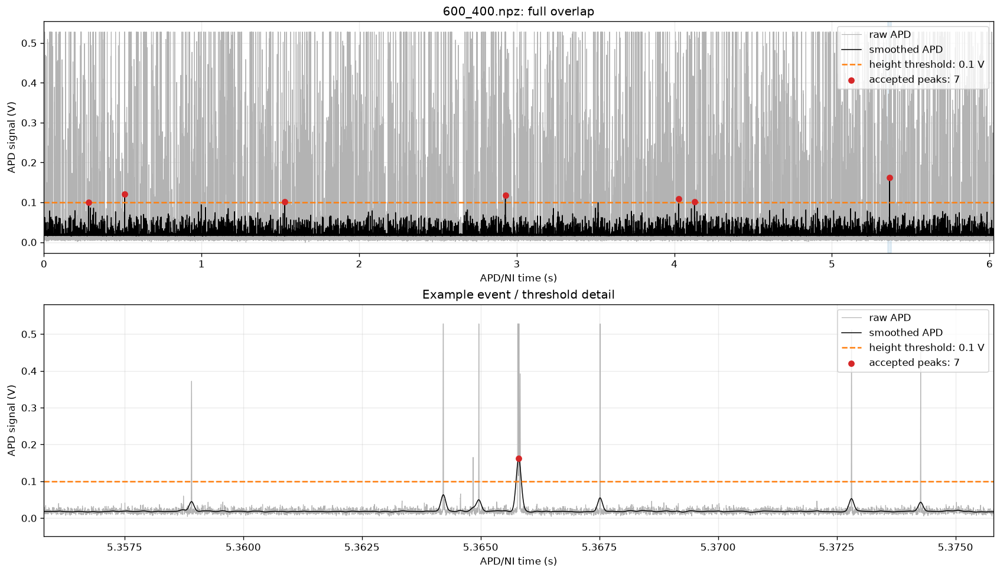

Height threshold: 0.1 V; prominence threshold: 0.00363124 V; minimum spacing: 0.25 ms
Preview only: no clips or output files were written. Adjust ABSOLUTE_HEIGHT_V below and rerun this preview cell.


In [117]:
# Adjust these values and rerun ONLY this cell to compare thresholds.
ABSOLUTE_HEIGHT_V = 0.1  # Volts; None uses HEIGHT_SIGMA from Configuration.
PREVIEW_PAIR_INDEX = 3
PREVIEW_CENTER_S = None  # APD time in seconds; None selects an example automatically.
PREVIEW_WINDOW_MS = 20.0

preview_pairs, _, _ = discover_and_pair(ROOT, NAME_MATCH_MODE)
preview_pairs = preview_pairs.loc[preview_pairs["status"].eq("matched")].reset_index(drop=True)
if preview_pairs.empty:
    raise ValueError("No matched pairs found. Check ROOT and the discovery table.")
display(preview_pairs[["apd_file", "cine_file", "apd_path"]].rename_axis("PREVIEW_PAIR_INDEX"))
if not isinstance(PREVIEW_PAIR_INDEX, int) or not 0 <= PREVIEW_PAIR_INDEX < len(preview_pairs):
    raise ValueError(f"PREVIEW_PAIR_INDEX must be between 0 and {len(preview_pairs)-1}.")
example_pair = preview_pairs.iloc[PREVIEW_PAIR_INDEX]
threshold_example = process_pair(
    example_pair.apd_path, example_pair.cine_path, OUTPUT_ROOT,
    example_pair.match_method, threshold_preview=True,
    preview_center_s=PREVIEW_CENTER_S, preview_window_ms=PREVIEW_WINDOW_MS,
)

APD samples: 10,000,000; rate: 500,000.0 Hz; trigger: 0.100770 s
CINE frames: 2,094,608; frame shape/dtype: (128, 256), uint16
Header FPS: 200,000.000; timestamp FPS: 198,107.348
Frames relative to trigger: -4.648374 to 5.924407 s
Overlap on APD clock: 0.000000 to 6.025183 s


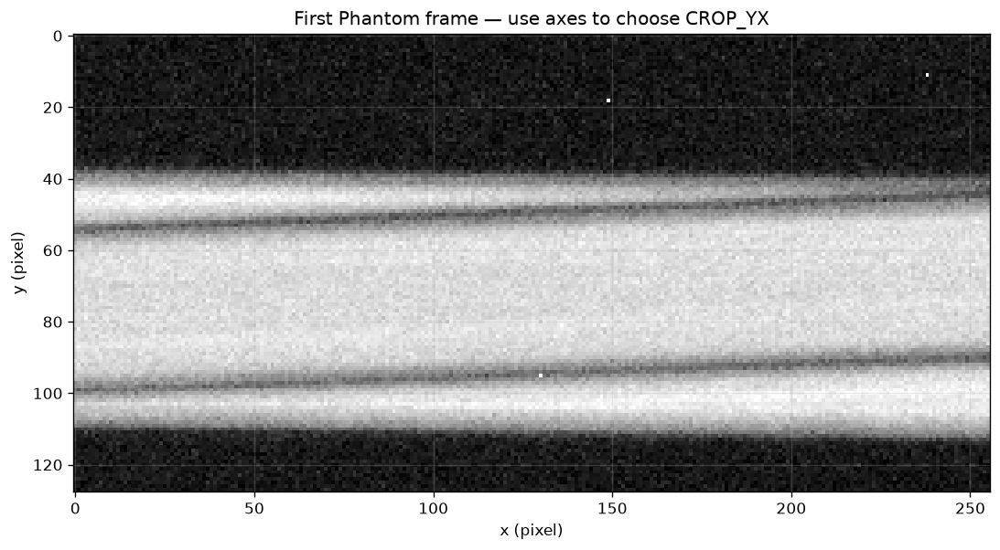

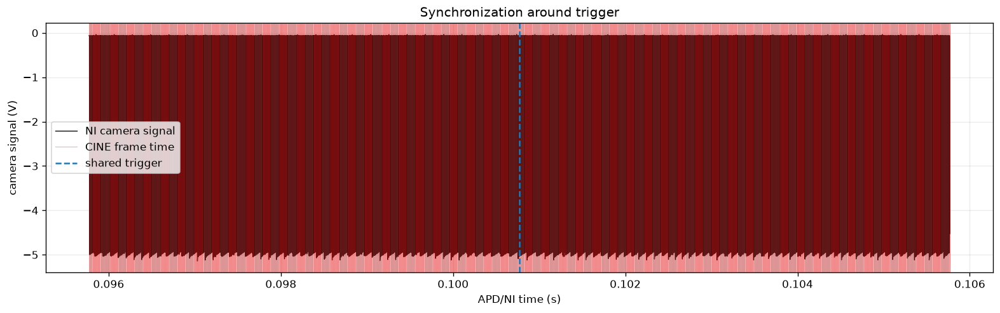

Camera levels: -4.880, -0.115 V; detected edges: 1,981,166
APD baseline: 0.0182849 V; noise σ: 0.00090781 V; height threshold: 0.1 V
Detected 7 event(s) in the APD/CINE overlap.


,event_id,peak_sample,peak_time_s,peak_end_time_s,apd_raw_v,apd_filtered_v,prominence_v,center_cine_frame,peak_end_cine_frame,center_frame_time_s,peak_minus_frame_ms,clip_start_frame,clip_stop_frame_exclusive,clip_frame_count,frames_after_peak_end
0,1,141258,0.282516,0.282683,0.527846,0.100301,0.084592,956910,956943,0.282517,-0.000738,956712,957108,396,164
1,2,256195,0.512390,0.512525,0.527846,0.120308,0.104786,1002451,1002478,0.512390,-0.000345,1002253,1002650,397,171
2,3,763797,1.527594,1.527732,0.019071,0.101029,0.085460,1203576,1203604,1.527593,0.001328,1203379,1203775,396,170
3,4,1463938,2.927876,2.928004,0.274213,0.117348,0.101926,1480991,1481016,2.927878,-0.001838,1480793,1481189,396,172
4,5,2013326,4.026652,4.026797,0.035326,0.109564,0.093850,1698673,1698701,4.026654,-0.001590,1698475,1698871,396,169
5,6,2063766,4.127532,4.127674,0.410236,0.101881,0.086067,1718658,1718686,4.127530,0.001749,1718461,1718857,396,170
6,7,2682901,5.365802,5.365947,0.268107,0.161553,0.146374,1963976,1964005,5.365802,0.000004,1963778,1964175,397,169


c:\Users\labfischer\.venvs\apd-phantom-cine\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


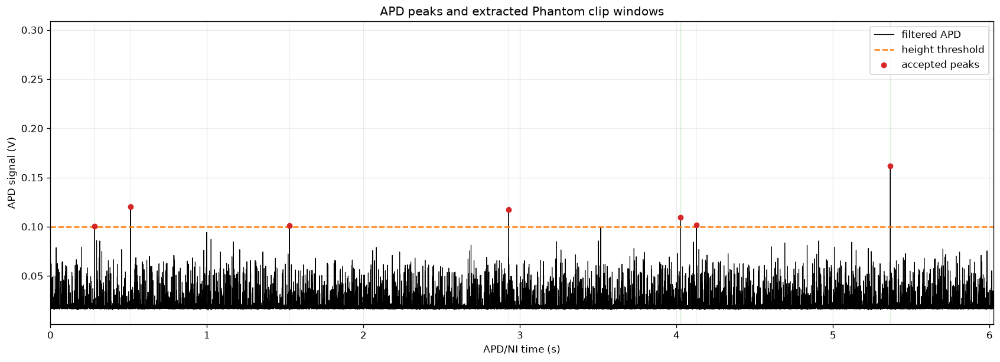

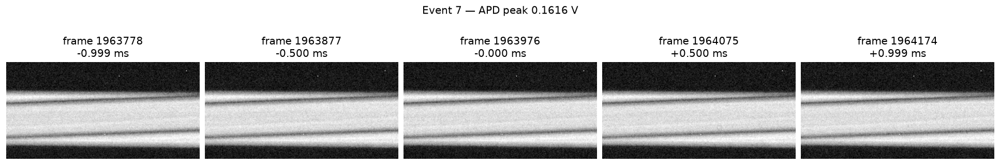

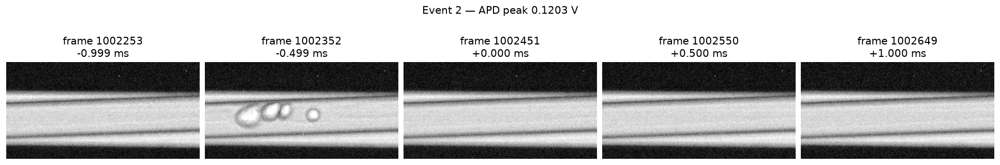

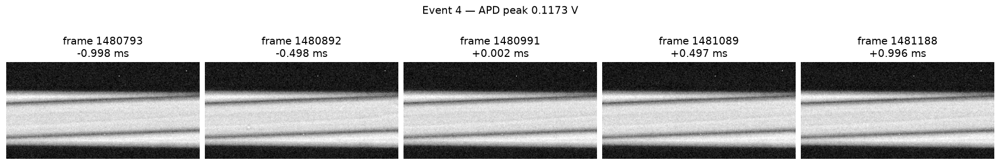

Saved event 1 (396 frames)
Saved event 2 (397 frames)
Saved event 3 (396 frames)
Saved event 4 (396 frames)
Saved event 5 (396 frames)
Saved event 6 (396 frames)
Saved event 7 (397 frames)
Finished: D:\Luise\APD\170926\NIH3T3\phantom_event_clips_single\600_400


In [118]:
SAVE_EVENT_CLIPS = True
SAVE_TIFF = True

relative_apd = Path(example_pair.apd_path).relative_to(ROOT)
output_dir = OUTPUT_ROOT / relative_apd.parent / relative_apd.stem

result = process_pair(
    example_pair.apd_path,
    example_pair.cine_path,
    output_dir,
    example_pair.match_method,
    show_previews=True,
)

## Run all matched pairs
After adjusting the threshold above, set `RUN_BATCH = True` in this cell and run it. It uses the current threshold. Failures are reported in `batch_summary` and processing continues with the remaining pairs.

In [ ]:
def run_batch(root, output_root, show_previews=False):
    """Rediscover matches so the run always uses the currently selected folder."""
    root = Path(root).expanduser().resolve()
    output_root = Path(output_root).expanduser().resolve()
    pairs, unused, errors = discover_and_pair(root, NAME_MATCH_MODE)
    matched = pairs.loc[pairs["status"].eq("matched")].copy()
    skipped = pairs.loc[~pairs["status"].eq("matched")].copy()
    print(f"Matched pairs: {len(matched)}; skipped APD files: {len(skipped)}; unused CINE files: {len(unused)}")
    if not skipped.empty:
        display(skipped[["apd_file", "apd_path", "status"]])
    for error in errors:
        print(f"Discovery warning: {error}")
    if matched.empty:
        raise ValueError(f"No unambiguous APD/CINE matches found under {root}.")

    if SAVE_EVENT_CLIPS:
        output_root.mkdir(parents=True, exist_ok=True)
    results = []
    for number, pair in enumerate(matched.itertuples(index=False), start=1):
        relative_apd = Path(pair.apd_path).relative_to(root)
        output_dir = output_root / relative_apd.parent / relative_apd.stem
        print(f"\n[{number}/{len(matched)}] {relative_apd} -> {Path(pair.cine_path).name}")
        result = {"apd_path": pair.apd_path, "cine_path": pair.cine_path,
                  "match_method": pair.match_method, "output_dir": str(output_dir),
                  "status": "failed", "event_count": None, "actual_fps": None,
                  "exported": False, "error": ""}
        try:
            result.update(process_pair(pair.apd_path, pair.cine_path, output_dir,
                                       pair.match_method, show_previews))
            result["status"] = "completed"
        except Exception as exc:
            result["error"] = f"{type(exc).__name__}: {exc}"
            print(f"FAILED: {result['error']}")
        results.append(result)
        # Save progress after every pair, including failures.
        if SAVE_EVENT_CLIPS:
            pd.DataFrame(results).to_csv(output_root / "batch_summary.csv", index=False)
    summary = pd.DataFrame(results)
    print(f"\nCompleted: {summary['status'].eq('completed').sum()}; failed: {summary['status'].eq('failed').sum()}")
    if SAVE_EVENT_CLIPS:
        print(f"Summary: {output_root / 'batch_summary.csv'}")
    return summary

# Set True after inspecting the threshold preview, then run this cell.
RUN_BATCH = True











if RUN_BATCH:
    batch_summary = run_batch(ROOT, OUTPUT_ROOT, show_previews=SHOW_PREVIEWS)
    display(batch_summary)
else:
    print("Inspect the threshold preview above, then set RUN_BATCH = True in this cell to process all matches.")

Matched pairs: 6; skipped APD files: 0; unused CINE files: 0

[1/6] 100_50_BF.npz -> 100_50_BF.cine
APD samples: 15,000,000; rate: 500,000.0 Hz; trigger: 0.100246 s
CINE frames: 2,094,608; frame shape/dtype: (128, 256), uint16
Header FPS: 70,000.000; timestamp FPS: 70,000.771
Frames relative to trigger: -19.217747 to 10.705215 s
Overlap on APD clock: 0.000000 to 10.805476 s
APD baseline: 0.107403 V; noise σ: 0.00185878 V; height threshold: 0.15 V
Detected 2025 event(s) in the APD/CINE overlap.
Saved event 1 (420 frames)
Saved event 2 (420 frames)
Saved event 3 (420 frames)
Saved event 4 (420 frames)
Saved event 5 (420 frames)
Saved event 6 (420 frames)
Saved event 7 (420 frames)
Saved event 8 (420 frames)
Saved event 9 (420 frames)
Saved event 10 (420 frames)
Saved event 11 (420 frames)
Saved event 12 (420 frames)
Saved event 13 (420 frames)
Saved event 14 (420 frames)
Saved event 15 (420 frames)
Saved event 16 (420 frames)
Saved event 17 (420 frames)
Saved event 18 (420 frames)
Saved 

,apd_path,cine_path,match_method,output_dir,status,event_count,actual_fps,exported,error
0,D:\Luise\APD\210926\NIH3T3\100_50_BF.npz,D:\Luise\APD\210926\NIH3T3\100_50_BF.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,2025,70000.770846,True,
1,D:\Luise\APD\210926\NIH3T3\100_50_Ph2.npz,D:\Luise\APD\210926\NIH3T3\100_50_Ph2.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,344,70000.770846,True,
2,D:\Luise\APD\210926\NIH3T3\200_100_BF.npz,D:\Luise\APD\210926\NIH3T3\200_100_BF.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,900,100003.895315,True,
3,D:\Luise\APD\210926\NIH3T3\200_100_Ph2.npz,D:\Luise\APD\210926\NIH3T3\200_100_Ph2.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,5,100003.895315,True,
4,D:\Luise\APD\210926\NIH3T3\20_10_BF.npz,D:\Luise\APD\210926\NIH3T3\20_10_BF.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,14745,62499.524098,True,
5,D:\Luise\APD\210926\NIH3T3\20_10_Ph2.npz,D:\Luise\APD\210926\NIH3T3\20_10_Ph2.cine,exact stem,D:\Luise\APD\210926\NIH3T3\phantom_event_clips...,completed,13200,62499.524098,True,
